# 03 — Senior Population by Comarca: Size, Concentration, Trends and Projections

## 1. Objective and research questions

**Objective.** Quantify and characterise the senior population of Catalonia **by comarca** (42 comarques + Aran), as the demographic basis for the market study. This notebook describes the *potential population base*. It does **not** measure demand: being 60+ does not make anyone a customer.

**Research questions**

1. **Size.** How many people aged 60+, 65+ and 75+ live in each comarca (1 Jan 2025)?
2. **Concentration.** In which comarques do seniors make up the largest share of residents? How concentrated is the senior population across comarques?
3. **Threshold sensitivity.** Do comarca rankings change when the threshold is 60+, 65+ or 75+?
4. **Recent trends.** How did the senior population change in 2011–2025 and 2021–2025 within *constant* comarca boundaries?
5. **Projections.** How is it projected to change up to 2040, according to Idescat's official projections (three scenarios)?
6. **Context.** How do senior size and share sit alongside household income (RFDB 2023) and seasonal population (ETCA 2024)? This is descriptive only, with no composite score.

**Scope.** Catalonia, comarca level, comarca division in force on **1 January 2025**. Notebooks 01–02 (municipal, exploratory) are left unchanged. This notebook corrects their known issues: it removes aggregate rows, joins by code, and states the year of every indicator (see `docs/existing_work_review.md`).

## 2. Data sources

All data come from **Idescat** (Institut d'Estadística de Catalunya). Raw files are stored unmodified in `data/raw/` and documented in `docs/data_sources.md`. API downloads are reproducible with `python scripts/download_idescat.py`, which records each file's URL, retrieval time and SHA-256 in `data/raw/idescat_api/MANIFEST.csv`.

| ID | Dataset | Reference | Geography | File |
|---|---|---|---|---|
| DS-04 | Census: population by sex and five-year age (`censph` 539/5976) | 1 Jan 2025 | Comarca | `data/raw/comarca/censph-539-5976-com.csv` (uploaded by the author) |
| DS-07 | Same census table, all years | 2011, 2021–2025 | Comarca (boundaries in force each year) | `data/raw/idescat_api/censph_539_5976_com.json` |
| DS-08 | Same census table, sex = total | 2011, 2021–2025 | **Municipality** | `data/raw/idescat_api/censph_539_5976_mun_*.json` |
| DS-09 | Population estimates by five-year age (`ep` 9124/20150) | 1 Jan 2012–2025 | Comarca (boundaries in force each period) | `data/raw/idescat_api/ep_9124_20150_com_S1_total.json` |
| DS-10 | Population projections, base 2024, low / medium / high scenarios (`proj`) | 2024–2049 | Comarca (1 Jan 2025 division) | `data/raw/idescat_api/proj_*_com_*.json` |
| DS-11 | Territorial codes: municipality → comarca | Current division | Municipality | `data/raw/idescat_api/codis_municipis_comarques.csv` |
| DS-05 | RFDB (household gross disposable income), provisional | 2023 | Comarca | `data/raw/comarca/rfdbc-21181-25017-com.csv` |
| DS-06 | Seasonal population ETCA by quarter | 2024 | Comarca | `data/raw/comarca/idescat-aec-15960-1.csv` |

Source attribution: *Idescat. Cens de població i habitatges; Estimacions de població; Projeccions de població (base 2024); Renda familiar disponible bruta territorial; Estimacions de població estacional.*

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project root, independent of where the notebook is launched
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from tfg.idescat import read_jsonstat, age_group_lower_bound
from tfg.territory import municipality_to_comarca_2025, COMARCA_OVERRIDES_2025_01_01
from tfg.paths import IDESCAT_API_RAW, COMARCA_RAW, DATA_PROCESSED, REPORTS_FIGURES

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
REPORTS_FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

THRESHOLDS = {"60_plus": 60, "65_plus": 65, "75_plus": 75}
CATALONIA = "Catalunya"
print("pandas", pd.__version__)

pandas 3.1.0


## 3. Data preparation

### 3.1 Helper: senior indicators from five-year age groups

Every source uses the same 21 five-year age groups (`0–4` … `95–99`, `100+`) plus a `total`. Because the thresholds 60, 65 and 75 fall exactly on group boundaries, the 60+, 65+ and 75+ aggregates are **exact** sums, not interpolations. We also compute the *60–74* band, a commonly used "young-old" segment, and 0–14 for the ageing index (65+ / 0–14 × 100, Idescat's definition).

In [2]:
def senior_indicators(df, keys, age_col="age_lower", value_col="population", total_flag="is_total"):
    # Return population totals and senior aggregates per `keys`.
    # `df` has one row per (keys, age group) plus one row with total_flag=True.
    ages = df.loc[~df[total_flag]]
    totals = df.loc[df[total_flag]].set_index(keys)[value_col].rename("pop_total")
    out = pd.DataFrame(totals)
    for name, lower in THRESHOLDS.items():
        out[f"pop_{name}"] = ages.loc[ages[age_col] >= lower].groupby(keys)[value_col].sum()
    out["pop_60_74"] = ages.loc[ages[age_col].between(60, 74)].groupby(keys)[value_col].sum()
    out["pop_0_14"] = ages.loc[ages[age_col] < 15].groupby(keys)[value_col].sum()
    # Validation: age groups must add up to the published total (exact for 2021+)
    out["age_sum"] = ages.groupby(keys)[value_col].sum()
    for name in list(THRESHOLDS) + ["60_74"]:
        out[f"share_{name}"] = 100 * out[f"pop_{name}"] / out["pop_total"]
    out["ageing_index"] = 100 * out["pop_65_plus"] / out["pop_0_14"]
    return out.reset_index()


def tidy_age(df, age_label_col):
    df = df.copy()
    df["age_lower"] = df[age_label_col].map(age_group_lower_bound)
    df["is_total"] = df[age_label_col].astype(str).str.lower().isin(["total", "totals"])
    assert df.loc[~df["is_total"], "age_lower"].notna().all()
    return df

### 3.2 Census 2025 by comarca (DS-04, the author's file), checked against the API (DS-07)

In [3]:
census_2025_raw = pd.read_csv(COMARCA_RAW / "censph-539-5976-com.csv", sep=";", encoding="utf-8-sig")
print(census_2025_raw.shape)
assert census_2025_raw["any"].eq(2025).all()
assert not census_2025_raw.duplicated(["comarca o Aran", "edat quinquennal", "sexe"]).any()
assert census_2025_raw["valor"].notna().all()

census_2025 = (census_2025_raw
               .loc[census_2025_raw["sexe"] == "total"]
               .rename(columns={"comarca o Aran": "comarca", "valor": "population"}))
census_2025 = tidy_age(census_2025, "edat quinquennal")

# Same table from the API (all years, boundaries in force in each year)
census_com_api = read_jsonstat(IDESCAT_API_RAW / "censph_539_5976_com.json")
check = census_2025_raw.merge(
    census_com_api.loc[census_com_api["YEAR"] == "2025"],
    left_on=["comarca o Aran", "edat quinquennal", "sexe"],
    right_on=["COM_label", "AGE_label", "SEX_label"], how="outer", indicator=True)
assert check["_merge"].eq("both").all()
print("Cells compared:", len(check), "| mismatches:", int((check["valor"] != check["value"]).sum()))

(2904, 7)
Cells compared: 2904 | mismatches: 0


In [4]:
indicators_2025 = senior_indicators(census_2025, keys=["comarca"])
assert (indicators_2025["age_sum"] == indicators_2025["pop_total"]).all()

catalonia_2025 = indicators_2025.loc[indicators_2025["comarca"] == CATALONIA].iloc[0]
comarca_2025 = indicators_2025.loc[indicators_2025["comarca"] != CATALONIA].copy()
assert len(comarca_2025) == 43

# Comarques must add up exactly to Catalonia (aggregate row removed above)
for col in ["pop_total", "pop_60_plus", "pop_65_plus", "pop_75_plus"]:
    assert comarca_2025[col].sum() == catalonia_2025[col], col
print("43 comarques reconcile with the Catalonia totals for all thresholds.")

43 comarques reconcile with the Catalonia totals for all thresholds.


### 3.3 Constant-boundary series 2011–2025 from municipal census data (DS-08 + DS-11)

The comarca tables use the boundaries **in force in each year**. Between 2011 and 2025 these changed: Moianès was created (2015), Biosca and Torà moved from Segarra to Solsonès, and Lluçanès was created (2023). Comparing published comarca figures across years would mix demographic change with boundary change.

**Method:** aggregate the *municipal* census figures for every year to the **1 Jan 2025 division**. The Idescat code list reflects the *current* division, which already includes the July 2025 move of Aiguafreda from Vallès Oriental to Osona (Llei 7/2025). That move is reverted explicitly (`src/tfg/territory.py`). The aggregation is then checked against the published 2024 and 2025 comarca tables, which must match exactly.

In [5]:
mun_to_comarca = municipality_to_comarca_2025()
print("Municipalities:", len(mun_to_comarca), "| comarques:", mun_to_comarca["comarca_name"].nunique())
print("Overrides applied:", COMARCA_OVERRIDES_2025_01_01)
display(mun_to_comarca.loc[mun_to_comarca["override_applied"]])

census_mun = pd.concat(
    [read_jsonstat(f) for f in sorted(IDESCAT_API_RAW.glob("censph_539_5976_mun_*_total_*.json"))],
    ignore_index=True)
census_mun = census_mun.loc[census_mun["MUN"] != "TOTAL"]           # drop the Catalonia aggregate
assert not census_mun.duplicated(["YEAR", "MUN", "AGE"]).any()
assert census_mun["value"].notna().all()
print("Years:", sorted(census_mun["YEAR"].unique()), "| municipalities per year:",
      census_mun.groupby("YEAR")["MUN"].nunique().unique())

census_mun = census_mun.merge(mun_to_comarca[["mun_code", "comarca_name"]],
                              left_on="MUN", right_on="mun_code", how="left", validate="many_to_one")
assert census_mun["comarca_name"].notna().all(), "every municipality must map to a comarca"

census_mun = census_mun.rename(columns={"YEAR": "year", "comarca_name": "comarca", "value": "population"})
census_mun = tidy_age(census_mun, "AGE")
census_constant = (census_mun.groupby(["year", "comarca", "AGE", "age_lower", "is_total"], dropna=False)
                   ["population"].sum().reset_index())
census_constant["year"] = census_constant["year"].astype(int)

Municipalities: 947 | comarques: 43
Overrides applied: {'080142': ('41', 'Vallès Oriental')}


,mun_code,mun_name,comarca_code,comarca_name,comarca_code_current,comarca_name_current,override_applied
6,080142,Aiguafreda,41,Vallès Oriental,24,Osona,True


Years: ['2011', '2021', '2022', '2023', '2024', '2025'] | municipalities per year: [947]


In [6]:
# Reconcile with the published comarca tables (boundaries in force each year)
published = census_com_api.loc[(census_com_api["SEX"] == "TOTAL") & (census_com_api["COM"] != "TOTAL")
                               & (census_com_api["AGE"] == "TOTAL"),
                               ["YEAR", "COM_label", "value"]]
published = published.assign(year=published["YEAR"].astype(int)).rename(
    columns={"COM_label": "comarca", "value": "published"})
rebuilt = census_constant.loc[census_constant["is_total"], ["year", "comarca", "population"]]
reconciliation = rebuilt.merge(published[["year", "comarca", "published"]], on=["year", "comarca"], how="left")
reconciliation["difference"] = reconciliation["population"] - reconciliation["published"]

summary = (reconciliation.assign(differs=reconciliation["difference"].abs() > 0,
                                 not_published=reconciliation["published"].isna())
           .groupby("year")[["differs", "not_published"]].sum())
display(summary)

# The 1 Jan 2025 division is the one in force in 2024 and 2025: must match exactly
assert reconciliation.loc[reconciliation["year"].isin([2024, 2025]), "difference"].eq(0).all()
print("2024 and 2025: rebuilt comarques = published comarques (exact).")

big = reconciliation.loc[reconciliation["difference"].abs() > 5].sort_values(["year", "comarca"])
print("Differences larger than 5 people (expected: comarques affected by boundary changes):")
display(big)

,differs,not_published
year,,
2011,30,2
2021,3,1
2022,3,1
2023,3,1
2024,0,0
2025,0,0


2024 and 2025: rebuilt comarques = published comarques (exact).
Differences larger than 5 people (expected: comarques affected by boundary changes):


,year,comarca,population,published,difference
7,2011,Bages,176796.0,185605.0,-8809.0
26,2011,Osona,148196.0,154103.0,-5907.0
34,2011,Segarra,21675.0,23191.0,-1516.0
37,2011,Solsonès,15190.0,13676.0,1514.0
42,2011,Vallès Oriental,397096.0,400900.0,-3804.0
69,2021,Osona,158361.0,163867.0,-5506.0
77,2021,Segarra,22024.0,23455.0,-1431.0
80,2021,Solsonès,15079.0,13648.0,1431.0
112,2022,Osona,159196.0,164779.0,-5583.0
120,2022,Segarra,22169.0,23614.0,-1445.0


**Reading the reconciliation.** In 2024–2025 the rebuilt and published comarques are identical. In 2021–2023 the only differences above 5 people are in **Osona** (whose published figure still includes the municipalities that formed Lluçanès in 2023; Lluçanès is not published for those years) and **Segarra / Solsonès** (Biosca and Torà, moved in 2023). In 2011 there are also **Bages, Osona and Vallès Oriental** (municipalities that formed Moianès in 2015; Moianès and Lluçanès are not published), plus differences of a few people in other comarques. Those come from Idescat's rounding of the partly survey-based 2011 census (see the table note). These are exactly the documented boundary changes, so the constant-boundary series is consistent.

In [7]:
trends = senior_indicators(census_constant, keys=["year", "comarca"])
# 2011 includes survey-based, rounded data: age groups may not add up exactly to totals
gap = (trends["age_sum"] - trends["pop_total"]).abs()
print("Max |age sum - total| by year:", gap.groupby(trends["year"]).max().to_dict())
assert gap[trends["year"] >= 2021].eq(0).all()

catalonia_trend = trends.groupby("year")[["pop_total", "pop_60_plus", "pop_65_plus", "pop_75_plus", "pop_60_74", "pop_0_14"]].sum()
for name in ["60_plus", "65_plus", "75_plus", "60_74"]:
    catalonia_trend[f"share_{name}"] = 100 * catalonia_trend[f"pop_{name}"] / catalonia_trend["pop_total"]
assert catalonia_trend.loc[2025, "pop_60_plus"] == catalonia_2025["pop_60_plus"]
display(catalonia_trend.round(2))

Max |age sum - total| by year: {2011: 45.0, 2021: 0.0, 2022: 0.0, 2023: 0.0, 2024: 0.0, 2025: 0.0}


,pop_total,pop_60_plus,pop_65_plus,pop_75_plus,pop_60_74,pop_0_14,share_60_plus,share_65_plus,share_75_plus,share_60_74
year,,,,,,,,,,
2011,7519838.0,1680053.0,1280748.0,669886.0,1010167.0,1183597.0,22.34,17.03,8.91,13.43
2021,7749896.0,1937138.0,1475591.0,730856.0,1206282.0,1143010.0,25.00,19.04,9.43,15.57
2022,7761823.0,1968485.0,1498168.0,742918.0,1225567.0,1122062.0,25.36,19.30,9.57,15.79
2023,7901963.0,2009437.0,1529164.0,758512.0,1250925.0,1116910.0,25.43,19.35,9.60,15.83
2024,8012231.0,2055002.0,1565498.0,782549.0,1272453.0,1097534.0,25.65,19.54,9.77,15.88
2025,8124126.0,2106500.0,1601987.0,802324.0,1304176.0,1079859.0,25.93,19.72,9.88,16.05


### 3.4 Population estimates 2012–2025 (DS-09): annual cross-check at Catalonia level

At the Catalonia level boundaries do not matter. The annual estimates fill the 2012–2020 gap in the census series and show whether the census years fit a consistent annual path.

In [8]:
estimates = read_jsonstat(IDESCAT_API_RAW / "ep_9124_20150_com_S1_total.json")
estimates = estimates.loc[estimates["COM"] == "TOTAL"].rename(columns={"value": "population"})
estimates["year"] = estimates["SEMESTER"].str[:4].astype(int)
estimates = tidy_age(estimates, "AGE")
catalonia_estimates = senior_indicators(estimates, keys=["year"]).set_index("year")
assert (catalonia_estimates["age_sum"] == catalonia_estimates["pop_total"]).all()

comparison = catalonia_trend[["pop_total", "pop_60_plus"]].merge(
    catalonia_estimates[["pop_total", "pop_60_plus"]], left_index=True, right_index=True,
    how="outer", suffixes=("_census", "_estimates"))
display(comparison)
same = comparison.dropna()
print("Years where census and estimates coincide exactly:", same.index[(same["pop_total_census"] == same["pop_total_estimates"])].tolist())

,pop_total_census,pop_60_plus_census,pop_total_estimates,pop_60_plus_estimates
year,,,,
2011,7519838.0,1680053.0,NaN,NaN
2012,NaN,NaN,7515398.0,1682023.0
2013,NaN,NaN,7481158.0,1707484.0
2014,NaN,NaN,7438060.0,1733137.0
2015,NaN,NaN,7430638.0,1758116.0
2016,NaN,NaN,7455671.0,1783568.0
2017,NaN,NaN,7504764.0,1812753.0
2018,NaN,NaN,7553681.0,1843089.0
2019,NaN,NaN,7629889.0,1876737.0


Years where census and estimates coincide exactly: [2021, 2022, 2023, 2024, 2025]


### 3.5 Projections, base 2024 (DS-10)

Idescat publishes three scenarios (low, medium, high). The projections use the 1 Jan 2025 comarca division, and their base year (2024) equals the 2024 census. Projected growth is always computed **within** the projection series (projected 2025 → projected year), so that observed and projected levels are not mixed.

In [9]:
projections_raw = pd.concat([read_jsonstat(f) for f in sorted(IDESCAT_API_RAW.glob("proj_*_com_*.json"))],
                            ignore_index=True)
assert projections_raw["value"].notna().all()
assert not projections_raw.duplicated(["SCEN", "YEAR", "COM", "AGE"]).any()
scenario_names = {"LSCE": "low", "MSCE": "medium", "HSCE": "high"}
projections = projections_raw.assign(
    scenario=projections_raw["SCEN"].map(scenario_names),
    year=projections_raw["YEAR"].astype(int),
    comarca=np.where(projections_raw["COM"] == "TOTAL", CATALONIA, projections_raw["COM_label"]),
).rename(columns={"value": "population"})
projections = tidy_age(projections, "AGE")
projected = senior_indicators(projections, keys=["scenario", "year", "comarca"])
assert (projected["age_sum"] == projected["pop_total"]).all()

# Base year equals the 2024 census in every scenario and comarca
base_2024 = projected.loc[projected["year"] == 2024].pivot(index="comarca", columns="scenario", values="pop_total")
census_2024 = trends.loc[trends["year"] == 2024].set_index("comarca")["pop_total"]
assert (base_2024.drop(index=CATALONIA).sub(census_2024, axis=0) == 0).all().all()
assert set(projected["comarca"]) - {CATALONIA} == set(comarca_2025["comarca"])
print("Projection base 2024 = census 2024 for all comarques and scenarios.")

Projection base 2024 = census 2024 for all comarques and scenarios.


### 3.6 Socioeconomic and seasonal context (DS-05, DS-06)

In [10]:
rfdb_raw = pd.read_csv(COMARCA_RAW / "rfdbc-21181-25017-com.csv", sep=";", encoding="utf-8-sig", decimal=",")
assert rfdb_raw["any"].eq(2023).all() and rfdb_raw["estat"].eq("p").all()
rfdb = (rfdb_raw.pivot(index="comarca o Aran", columns="indicador", values="valor")
        .rename(columns={"per habitant (€)": "rfdb_per_capita_eur_2023",
                         "per habitant (índex Catalunya=100)": "rfdb_index_cat100_2023",
                         "valor (milers €)": "rfdb_thousand_eur_2023"}))
rfdb.index.name = "comarca"

etca_raw = pd.read_csv(COMARCA_RAW / "idescat-aec-15960-1.csv", sep=";", encoding="utf-8-sig")
etca_raw["value_num"] = pd.to_numeric(etca_raw["value"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
etca = etca_raw.pivot(index="row", columns="col", values="value_num").rename(columns={
    "Población residente": "etca_resident_pop_2024",
    "Población estacional ETCA / Total": "etca_seasonal_total_2024",
    "Población estacional ETCA / T3": "etca_seasonal_q3_2024",
    "Población ETCA (%)": "etca_pct_of_resident_2024"})
etca = etca.drop(index="Cataluña")[["etca_resident_pop_2024", "etca_seasonal_total_2024",
                                    "etca_seasonal_q3_2024", "etca_pct_of_resident_2024"]]
etca.index.name = "comarca"
assert set(rfdb.index) - {CATALONIA} == set(comarca_2025["comarca"]) == set(etca.index)
# ETCA resident population is the 1 Jan 2024 figure
assert (etca["etca_resident_pop_2024"] == census_2024.reindex(etca.index)).all()
print("RFDB and ETCA cover all 43 comarques; ETCA residents = census 1 Jan 2024.")

RFDB and ETCA cover all 43 comarques; ETCA residents = census 1 Jan 2024.


## 4. Exploratory analysis

In [11]:
print(f"Catalonia, 1 Jan 2025 (census): {catalonia_2025.pop_total:,.0f} residents")
for name in ["60_plus", "65_plus", "75_plus", "60_74"]:
    print(f"  {name:8s}: {catalonia_2025['pop_' + name]:>10,.0f}  ({catalonia_2025['share_' + name]:.2f} %)")
print(f"  Ageing index (65+ per 100 aged 0-14): {catalonia_2025.ageing_index:.1f}")

display(comarca_2025[["pop_total", "pop_60_plus", "share_60_plus", "share_65_plus", "share_75_plus"]]
        .describe().round(2))

Catalonia, 1 Jan 2025 (census): 8,124,126 residents
  60_plus :  2,106,500  (25.93 %)
  65_plus :  1,601,987  (19.72 %)
  75_plus :    802,324  (9.88 %)
  60_74   :  1,304,176  (16.05 %)
  Ageing index (65+ per 100 aged 0-14): 148.4


,pop_total,pop_60_plus,share_60_plus,share_65_plus,share_75_plus
count,43.00,43.00,43.00,43.00,43.00
mean,188933.16,48988.37,27.98,21.18,10.40
std,401307.06,104168.29,3.43,2.94,1.86
min,4051.00,1148.00,22.07,16.45,7.42
25%,20429.50,5875.50,25.51,19.10,9.08
50%,47138.00,13724.00,26.87,20.37,9.86
75%,176627.00,44738.50,29.44,22.20,11.30
max,2398280.00,631118.00,36.55,29.16,16.08


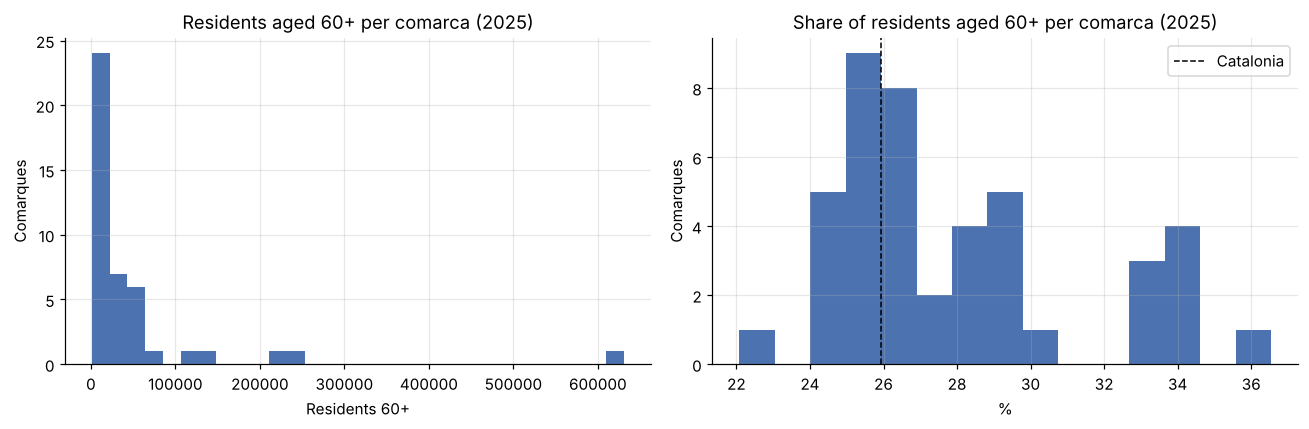

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(comarca_2025["pop_60_plus"], bins=30, color="#4C72B0")
axes[0].set(title="Residents aged 60+ per comarca (2025)", xlabel="Residents 60+", ylabel="Comarques")
axes[1].hist(comarca_2025["share_60_plus"], bins=15, color="#4C72B0")
axes[1].axvline(catalonia_2025["share_60_plus"], color="black", ls="--", lw=1, label="Catalonia")
axes[1].set(title="Share of residents aged 60+ per comarca (2025)", xlabel="%", ylabel="Comarques")
axes[1].legend()
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_distribution_size_share.png", bbox_inches="tight"); plt.show()

The absolute size is extremely skewed (Barcelonès is in a class of its own), while shares cluster within a much narrower range. Size and share therefore need to be read **separately**: a single combined ranking would be dominated by whichever variable the scaling favours.

## 5. Analytical methods

All methods are descriptive. No model is fitted, because none of the research questions needs one.

| Question | Method |
|---|---|
| Size and share | Exact sums of five-year age groups; share = group / total residents × 100. |
| Concentration | Cumulative share of Catalonia's 60+ population, with comarques sorted by size: how many comarques hold 50 % / 75 %. |
| Threshold sensitivity | Spearman rank correlation between the 60+, 65+ and 75+ rankings (pandas), plus overlap of the top 10. |
| Trends | Constant-boundary series. Absolute change, % change, and change in share (percentage points), for 2011→2025 and 2021→2025. |
| Projections | Idescat base 2024. Growth 2025→2035 and 2025→2040 within each scenario; low–high range as the uncertainty band. |
| Context | Side-by-side table and a scatter plot, with Spearman correlations reported as *descriptive associations* (n = 43, no inference, no causality). |

Deliberately **not** done: composite "opportunity scores" (decision D-007), clustering (premature at this stage), and causal interpretation.

## 6. Results

### 6.1 Size and share by comarca (1 Jan 2025)

In [13]:
table_2025 = comarca_2025.assign(
    share_of_catalonia_60_plus=100 * comarca_2025["pop_60_plus"] / catalonia_2025["pop_60_plus"],
    rank_size_60_plus=comarca_2025["pop_60_plus"].rank(ascending=False, method="min").astype(int),
    rank_share_60_plus=comarca_2025["share_60_plus"].rank(ascending=False, method="min").astype(int),
).sort_values("pop_60_plus", ascending=False)

cols = ["comarca", "pop_total", "pop_60_plus", "share_60_plus", "share_of_catalonia_60_plus",
        "pop_65_plus", "share_65_plus", "pop_75_plus", "share_75_plus", "ageing_index",
        "rank_size_60_plus", "rank_share_60_plus"]
display(table_2025[cols].round(1).reset_index(drop=True))

,comarca,pop_total,pop_60_plus,share_60_plus,share_of_catalonia_60_plus,pop_65_plus,share_65_plus,pop_75_plus,share_75_plus,ageing_index,rank_size_60_plus,rank_share_60_plus
0,Barcelonès,2398280,631118,26.3,30.0,491099,20.5,263441,11.0,173.1,1,26
1,Vallès Occidental,970228,236586,24.4,11.2,177249,18.3,85077,8.8,127.4,2,41
2,Baix Llobregat,856867,215903,25.2,10.2,163770,19.1,82783,9.7,139.9,3,36
3,Maresme,477375,128349,26.9,6.1,97240,20.4,46879,9.8,151.1,4,21
4,Vallès Oriental,431351,107069,24.8,5.1,79890,18.5,38211,8.9,135.8,5,38
5,Tarragonès,279332,68732,24.6,3.3,51571,18.5,24141,8.6,128.6,6,40
6,Segrià,221630,56189,25.4,2.7,41873,18.9,20693,9.3,136.3,7,34
7,Baix Camp,207529,52992,25.5,2.5,39634,19.1,18591,9.0,131.4,8,32
8,Bages,187620,51670,27.5,2.5,39332,21.0,19609,10.5,150.2,9,19
9,Selva,187308,48075,25.7,2.3,35695,19.1,16707,8.9,139.3,10,31


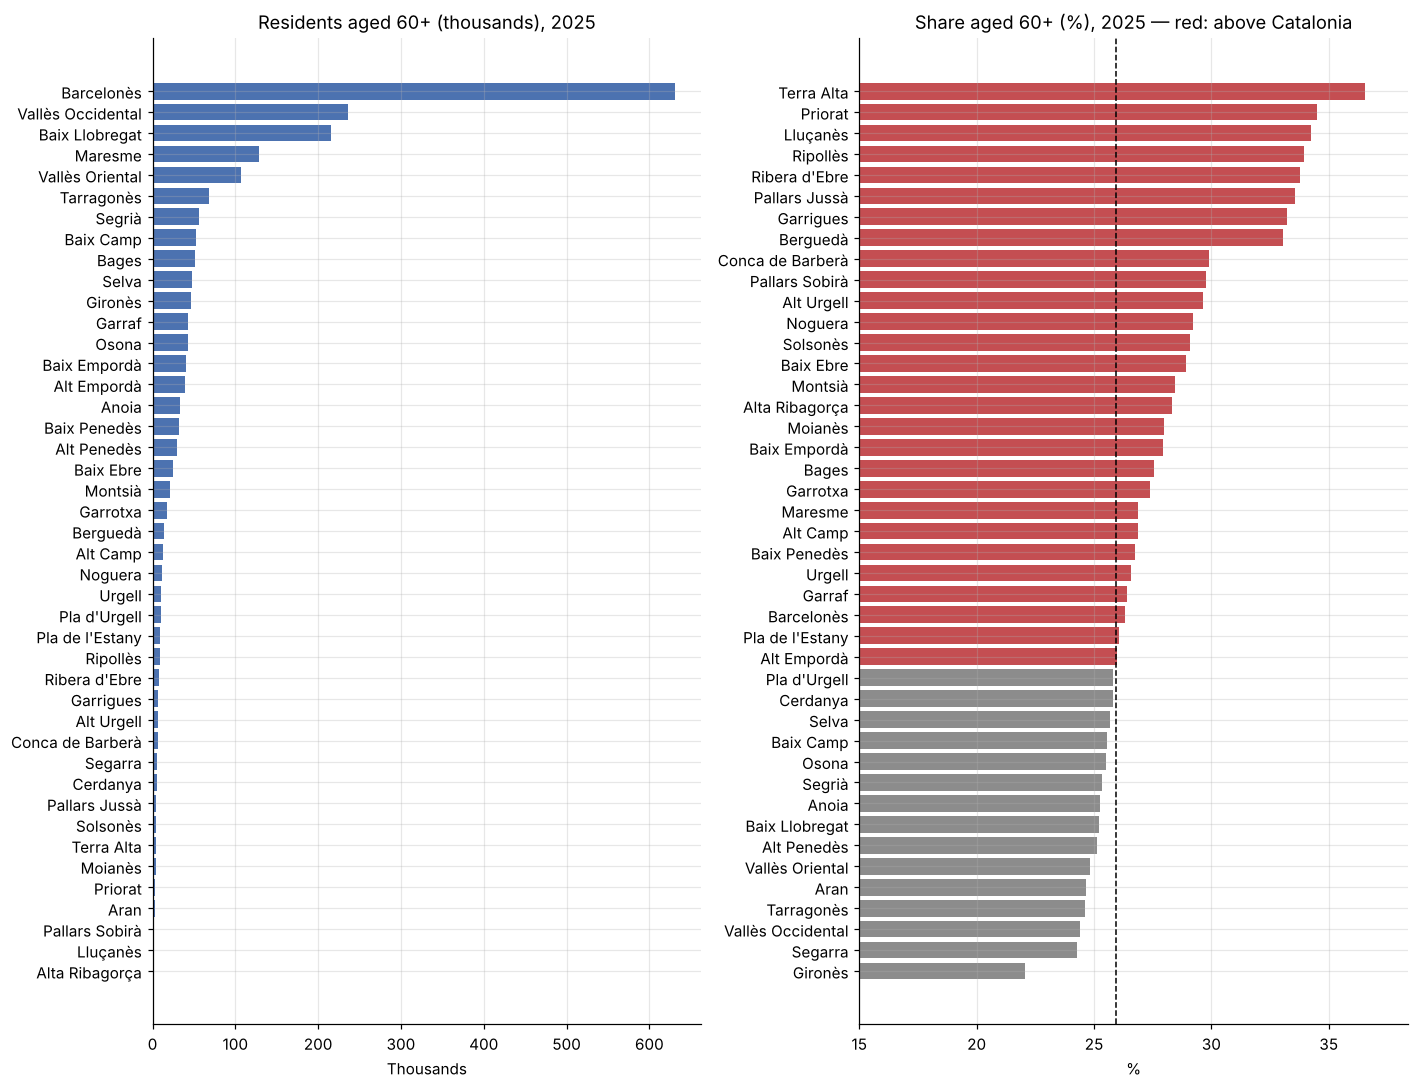

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 10), sharey=False)
order_size = table_2025.sort_values("pop_60_plus")
axes[0].barh(order_size["comarca"], order_size["pop_60_plus"] / 1000, color="#4C72B0")
axes[0].set(title="Residents aged 60+ (thousands), 2025", xlabel="Thousands")
order_share = table_2025.sort_values("share_60_plus")
colors = np.where(order_share["share_60_plus"] > catalonia_2025["share_60_plus"], "#C44E52", "#8C8C8C")
axes[1].barh(order_share["comarca"], order_share["share_60_plus"], color=colors)
axes[1].axvline(catalonia_2025["share_60_plus"], color="black", ls="--", lw=1)
axes[1].set(title="Share aged 60+ (%), 2025 — red: above Catalonia", xlabel="%")
axes[1].set_xlim(15, None)
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_size_and_share_60plus_2025.png", bbox_inches="tight"); plt.show()

### 6.2 Size versus concentration

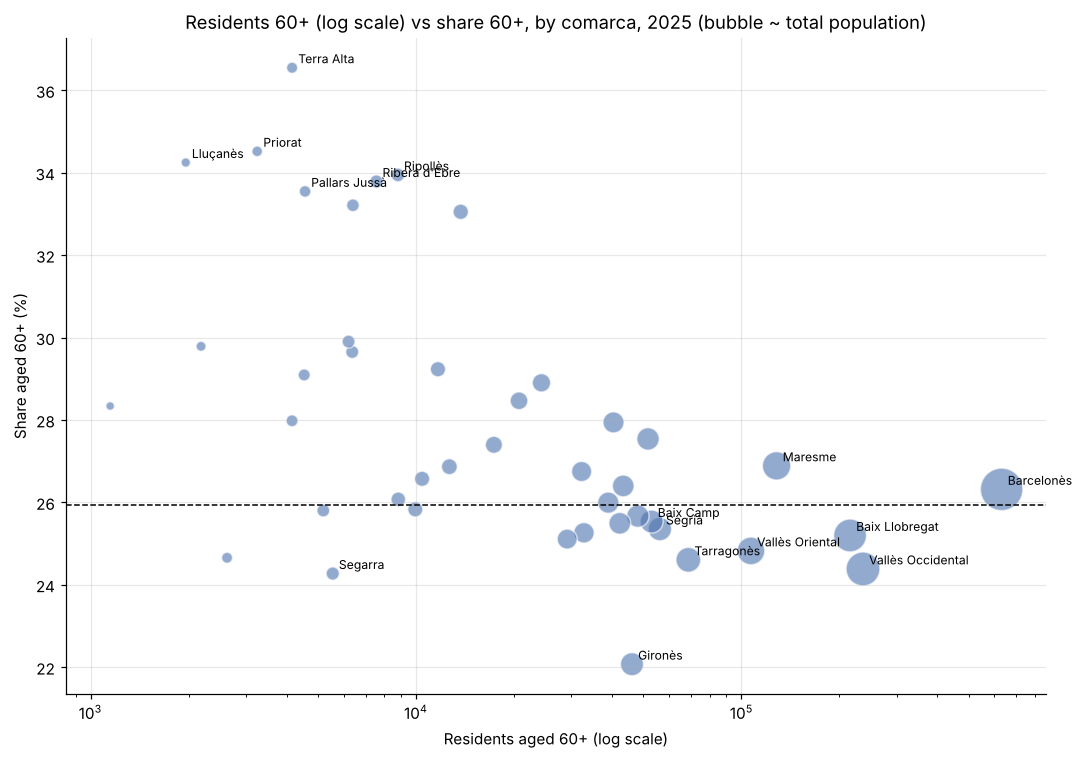

Spearman rank correlation, size vs share (60+): -0.58


In [15]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(table_2025["pop_60_plus"], table_2025["share_60_plus"],
           s=np.sqrt(table_2025["pop_total"]) / 2, alpha=0.6, color="#4C72B0", edgecolor="white")
ax.set_xscale("log")
ax.axhline(catalonia_2025["share_60_plus"], color="black", ls="--", lw=1)
label_these = set(table_2025.nlargest(8, "pop_60_plus")["comarca"]) | set(table_2025.nlargest(6, "share_60_plus")["comarca"]) \
              | set(table_2025.nsmallest(4, "share_60_plus")["comarca"])
for _, r in table_2025.loc[table_2025["comarca"].isin(label_these)].iterrows():
    ax.annotate(r["comarca"], (r["pop_60_plus"], r["share_60_plus"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(title="Residents 60+ (log scale) vs share 60+, by comarca, 2025 (bubble ~ total population)",
       xlabel="Residents aged 60+ (log scale)", ylabel="Share aged 60+ (%)")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_size_vs_share_2025.png", bbox_inches="tight"); plt.show()

rho_size_share = table_2025[["pop_60_plus", "share_60_plus"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman rank correlation, size vs share (60+): {rho_size_share:.2f}")

### 6.3 Concentration of the senior population across comarques

Comarques needed to reach 50 % of Catalonia's 60+: 3; 75 %: 10; 90 %: 18 (of 43)


,comarca,pop_60_plus,cumulative_share_pct
0,Barcelonès,631118,30.0
1,Vallès Occidental,236586,41.2
2,Baix Llobregat,215903,51.4
3,Maresme,128349,57.5
4,Vallès Oriental,107069,62.6
5,Tarragonès,68732,65.9
6,Segrià,56189,68.5
7,Baix Camp,52992,71.1
8,Bages,51670,73.5
9,Selva,48075,75.8


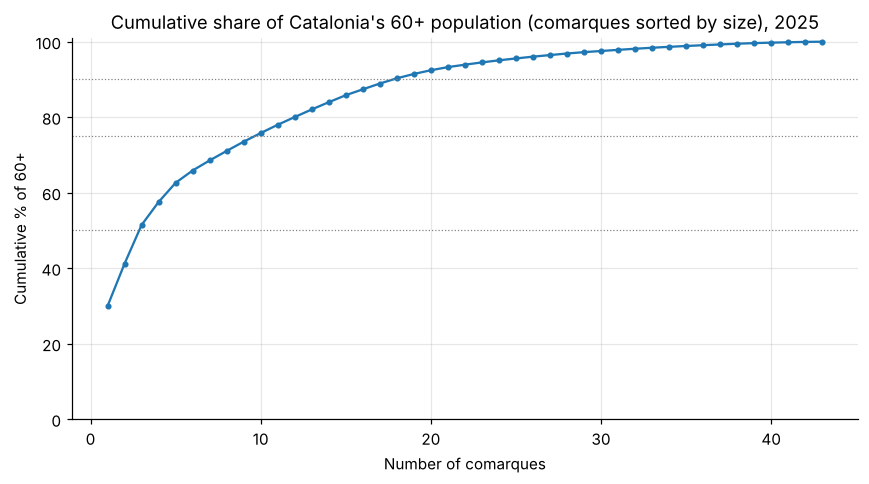

In [16]:
cumulative = table_2025.sort_values("pop_60_plus", ascending=False)[["comarca", "pop_60_plus"]].reset_index(drop=True)
cumulative["cumulative_share_pct"] = 100 * cumulative["pop_60_plus"].cumsum() / cumulative["pop_60_plus"].sum()
n50 = int((cumulative["cumulative_share_pct"] < 50).sum() + 1)
n75 = int((cumulative["cumulative_share_pct"] < 75).sum() + 1)
n90 = int((cumulative["cumulative_share_pct"] < 90).sum() + 1)
print(f"Comarques needed to reach 50 % of Catalonia's 60+: {n50}; 75 %: {n75}; 90 %: {n90} (of 43)")
display(cumulative.head(10).round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, 44), cumulative["cumulative_share_pct"], marker="o", ms=3)
for level in (50, 75, 90):
    ax.axhline(level, color="grey", lw=0.8, ls=":")
ax.set(title="Cumulative share of Catalonia's 60+ population (comarques sorted by size), 2025",
       xlabel="Number of comarques", ylabel="Cumulative % of 60+", ylim=(0, 101))
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_concentration_60plus_2025.png", bbox_inches="tight"); plt.show()

### 6.4 Sensitivity of rankings to the age threshold

In [17]:
size_cols = ["pop_60_plus", "pop_65_plus", "pop_75_plus"]
share_cols = ["share_60_plus", "share_65_plus", "share_75_plus"]
print("Spearman correlation between size rankings:")
display(comarca_2025[size_cols].corr(method="spearman").round(3))
print("Spearman correlation between share rankings:")
display(comarca_2025[share_cols].corr(method="spearman").round(3))

def top_overlap(col_a, col_b, k=10):
    a = set(comarca_2025.nlargest(k, col_a)["comarca"]); b = set(comarca_2025.nlargest(k, col_b)["comarca"])
    return len(a & b)

overlap = pd.DataFrame({
    "size (top 10)": [top_overlap("pop_60_plus", "pop_65_plus"), top_overlap("pop_60_plus", "pop_75_plus")],
    "share (top 10)": [top_overlap("share_60_plus", "share_65_plus"), top_overlap("share_60_plus", "share_75_plus")],
}, index=["60+ vs 65+", "60+ vs 75+"])
display(overlap)

top_share = pd.DataFrame({t: comarca_2025.nlargest(10, f"share_{t}")["comarca"].values for t in THRESHOLDS})
top_share.index = range(1, 11)
print("Top 10 comarques by share, per threshold:")
display(top_share)

Spearman correlation between size rankings:


,pop_60_plus,pop_65_plus,pop_75_plus
pop_60_plus,1.000,1.000,0.998
pop_65_plus,1.000,1.000,0.998
pop_75_plus,0.998,0.998,1.000


Spearman correlation between share rankings:


,share_60_plus,share_65_plus,share_75_plus
share_60_plus,1.000,0.983,0.920
share_65_plus,0.983,1.000,0.956
share_75_plus,0.920,0.956,1.000


,size (top 10),share (top 10)
60+ vs 65+,10,9
60+ vs 75+,10,9


Top 10 comarques by share, per threshold:


,60_plus,65_plus,75_plus
1,Terra Alta,Terra Alta,Terra Alta
2,Priorat,Priorat,Priorat
3,Lluçanès,Ripollès,Garrigues
4,Ripollès,Ribera d'Ebre,Pallars Jussà
5,Ribera d'Ebre,Pallars Jussà,Ribera d'Ebre
6,Pallars Jussà,Garrigues,Ripollès
7,Garrigues,Lluçanès,Berguedà
8,Berguedà,Berguedà,Lluçanès
9,Conca de Barberà,Conca de Barberà,Conca de Barberà
10,Pallars Sobirà,Alt Urgell,Baix Ebre


### 6.5 Recent trends at constant boundaries (2011 → 2021 → 2025)

2011 comes from a different census design (partly survey-based and rounded), whereas 2021+ comes from the register-based annual census. The **2021→2025** comparison is therefore the most homogeneous. **2011→2025** is shown for the longer view, with that caveat.

In [18]:
wide = trends.pivot(index="comarca", columns="year",
                    values=["pop_total", "pop_60_plus", "pop_75_plus", "share_60_plus", "share_75_plus"])

def change_table(start, end):
    t = pd.DataFrame(index=wide.index)
    t[f"pop_60_plus_{end}"] = wide[("pop_60_plus", end)]
    t["abs_change_60_plus"] = wide[("pop_60_plus", end)] - wide[("pop_60_plus", start)]
    t["pct_change_60_plus"] = 100 * t["abs_change_60_plus"] / wide[("pop_60_plus", start)]
    t["pct_change_total_pop"] = 100 * (wide[("pop_total", end)] / wide[("pop_total", start)] - 1)
    t["pp_change_share_60_plus"] = wide[("share_60_plus", end)] - wide[("share_60_plus", start)]
    t["pct_change_75_plus"] = 100 * (wide[("pop_75_plus", end)] / wide[("pop_75_plus", start)] - 1)
    return t

change_2021_2025 = change_table(2021, 2025)
change_2011_2025 = change_table(2011, 2025)

cat = catalonia_trend
for start in (2011, 2021):
    print(f"Catalonia {start}->2025: 60+ {cat.loc[2025,'pop_60_plus'] - cat.loc[start,'pop_60_plus']:+,.0f} "
          f"({100*(cat.loc[2025,'pop_60_plus']/cat.loc[start,'pop_60_plus']-1):+.1f} %), "
          f"total pop {100*(cat.loc[2025,'pop_total']/cat.loc[start,'pop_total']-1):+.1f} %, "
          f"share 60+ {cat.loc[start,'share_60_plus']:.2f} -> {cat.loc[2025,'share_60_plus']:.2f} % "
          f"({cat.loc[2025,'share_60_plus']-cat.loc[start,'share_60_plus']:+.2f} pp)")

print("\n2021 -> 2025, sorted by absolute change in 60+:")
display(change_2021_2025.sort_values("abs_change_60_plus", ascending=False).round(1))

Catalonia 2011->2025: 60+ +426,447 (+25.4 %), total pop +8.0 %, share 60+ 22.34 -> 25.93 % (+3.59 pp)
Catalonia 2021->2025: 60+ +169,362 (+8.7 %), total pop +4.8 %, share 60+ 25.00 -> 25.93 % (+0.93 pp)

2021 -> 2025, sorted by absolute change in 60+:


,pop_60_plus_2025,abs_change_60_plus,pct_change_60_plus,pct_change_total_pop,pp_change_share_60_plus,pct_change_75_plus
comarca,,,,,,
Barcelonès,631118.0,26604.0,4.4,5.7,-0.3,5.6
Vallès Occidental,236586.0,22772.0,10.7,3.5,1.6,13.3
Baix Llobregat,215903.0,19173.0,9.7,2.9,1.6,15.0
Maresme,128349.0,12914.0,11.2,3.7,1.8,14.1
Vallès Oriental,107069.0,11300.0,11.8,3.9,1.8,14.3
Tarragonès,68732.0,7836.0,12.9,6.3,1.4,15.8
Baix Camp,52992.0,6071.0,12.9,6.4,1.5,14.9
Selva,48075.0,5604.0,13.2,6.8,1.4,13.8
Garraf,43353.0,5478.0,14.5,6.5,1.8,15.8


In [19]:
print("2011 -> 2025 (longer view; 2011 survey-based census), sorted by % change in 60+:")
display(change_2011_2025.sort_values("pct_change_60_plus", ascending=False).round(1))

print("Comarques where the 60+ population decreased:")
print("  2021-2025:", change_2021_2025.index[change_2021_2025["abs_change_60_plus"] < 0].tolist())
print("  2011-2025:", change_2011_2025.index[change_2011_2025["abs_change_60_plus"] < 0].tolist())
print("Comarques where the 60+ share decreased:")
print("  2021-2025:", change_2021_2025.index[change_2021_2025["pp_change_share_60_plus"] < 0].tolist())

2011 -> 2025 (longer view; 2011 survey-based census), sorted by % change in 60+:


,pop_60_plus_2025,abs_change_60_plus,pct_change_60_plus,pct_change_total_pop,pp_change_share_60_plus,pct_change_75_plus
comarca,,,,,,
Aran,2626.0,999.0,61.4,6.3,8.4,20.8
Baix Penedès,32291.0,10855.0,50.6,20.0,5.4,65.9
Garraf,43353.0,14204.0,48.7,13.1,6.3,44.9
Tarragonès,68732.0,21059.0,44.2,11.9,5.5,37.2
Vallès Oriental,107069.0,31657.0,42.0,8.6,5.8,39.4
Selva,48075.0,13995.0,41.1,9.7,5.7,34.2
Maresme,128349.0,36401.0,39.6,9.9,5.7,37.4
Moianès,4159.0,1154.0,38.4,14.7,4.8,15.4
Gironès,46124.0,12759.0,38.2,14.8,3.7,15.9


Comarques where the 60+ population decreased:
  2021-2025: []
  2011-2025: ['Terra Alta']
Comarques where the 60+ share decreased:
  2021-2025: ['Barcelonès']


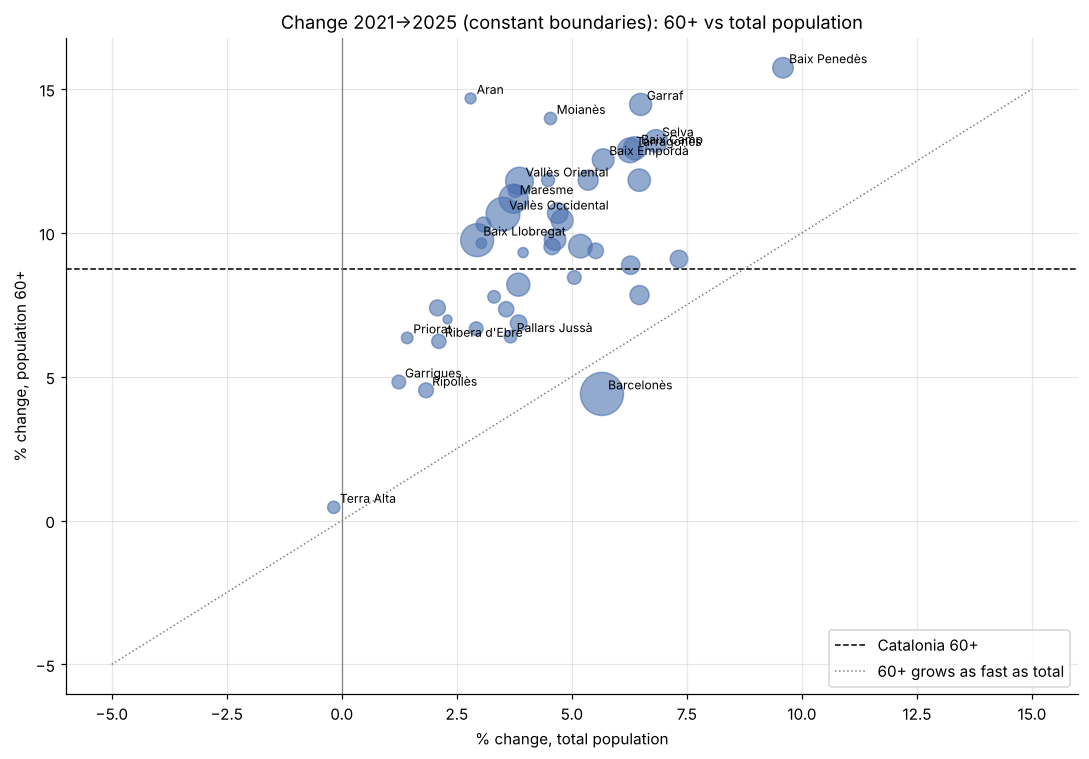

In [20]:
fig, ax = plt.subplots(figsize=(10, 7))
c = change_2021_2025
ax.scatter(c["pct_change_total_pop"], c["pct_change_60_plus"], s=np.sqrt(c["pop_60_plus_2025"]), alpha=0.6, color="#4C72B0")
ax.axhline(100 * (cat.loc[2025, "pop_60_plus"] / cat.loc[2021, "pop_60_plus"] - 1), color="black", ls="--", lw=1, label="Catalonia 60+")
ax.axvline(0, color="grey", lw=0.8)
ax.plot([-5, 15], [-5, 15], color="grey", ls=":", lw=1, label="60+ grows as fast as total")
for name, r in c.iterrows():
    if abs(r["pct_change_60_plus"] - c["pct_change_60_plus"].median()) > 3 or r["pop_60_plus_2025"] > 100_000:
        ax.annotate(name, (r["pct_change_total_pop"], r["pct_change_60_plus"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set(title="Change 2021→2025 (constant boundaries): 60+ vs total population",
       xlabel="% change, total population", ylabel="% change, population 60+")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_change_2021_2025.png", bbox_inches="tight"); plt.show()

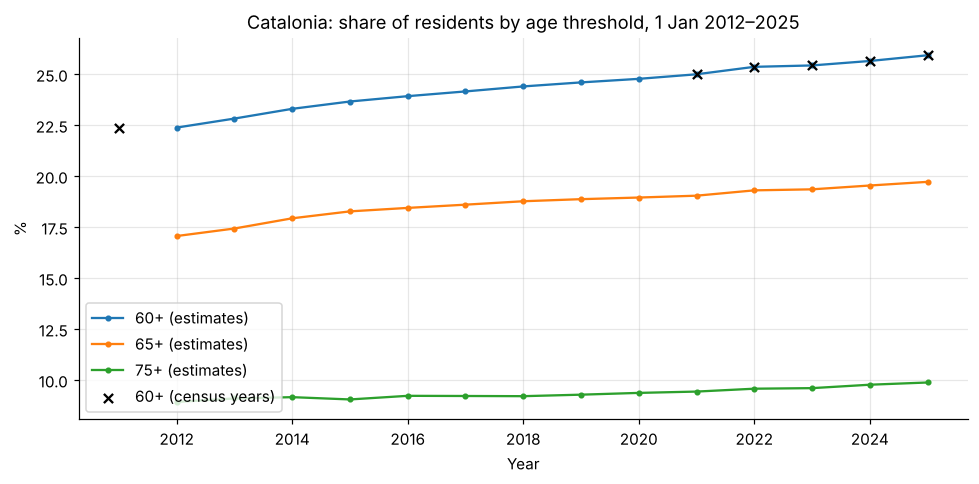

,pop_60_plus,share_60_plus,share_65_plus,share_75_plus
year,,,,
2012,1682023.0,22.38,17.06,8.92
2013,1707484.0,22.82,17.43,9.09
2014,1733137.0,23.30,17.93,9.16
2015,1758116.0,23.66,18.27,9.04
2016,1783568.0,23.92,18.44,9.22
2017,1812753.0,24.15,18.60,9.21
2018,1843089.0,24.40,18.77,9.20
2019,1876737.0,24.60,18.87,9.28
2020,1915570.0,24.77,18.95,9.37


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ce = catalonia_estimates
ax.plot(ce.index, ce["share_60_plus"], marker="o", ms=3, label="60+ (estimates)")
ax.plot(ce.index, ce["share_65_plus"], marker="o", ms=3, label="65+ (estimates)")
ax.plot(ce.index, ce["share_75_plus"], marker="o", ms=3, label="75+ (estimates)")
ax.scatter(cat.index, cat["share_60_plus"], color="black", marker="x", zorder=3, label="60+ (census years)")
ax.set(title="Catalonia: share of residents by age threshold, 1 Jan 2012–2025", ylabel="%", xlabel="Year")
ax.legend()
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_catalonia_shares_2012_2025.png", bbox_inches="tight"); plt.show()
display(ce[["pop_60_plus", "share_60_plus", "share_65_plus", "share_75_plus"]].round(2))

### 6.6 Projections to 2040 (Idescat, base 2024)

,,pop_total,pop_60_plus,share_60_plus,pop_75_plus,share_75_plus
scenario,year,,,,,
low,2025,8078162.0,2097441.0,26.0,796400.0,9.9
medium,2025,8112958.0,2104189.0,25.9,800313.0,9.9
high,2025,8151286.0,2110124.0,25.9,803367.0,9.9
low,2030,8195425.0,2300616.0,28.1,860216.0,10.5
medium,2030,8429457.0,2344314.0,27.8,883259.0,10.5
high,2030,8740437.0,2388232.0,27.3,902893.0,10.3
low,2035,8205869.0,2528077.0,30.8,949760.0,11.6
medium,2035,8585260.0,2609570.0,30.4,992679.0,11.6
high,2035,9068337.0,2691775.0,29.7,1030661.0,11.4


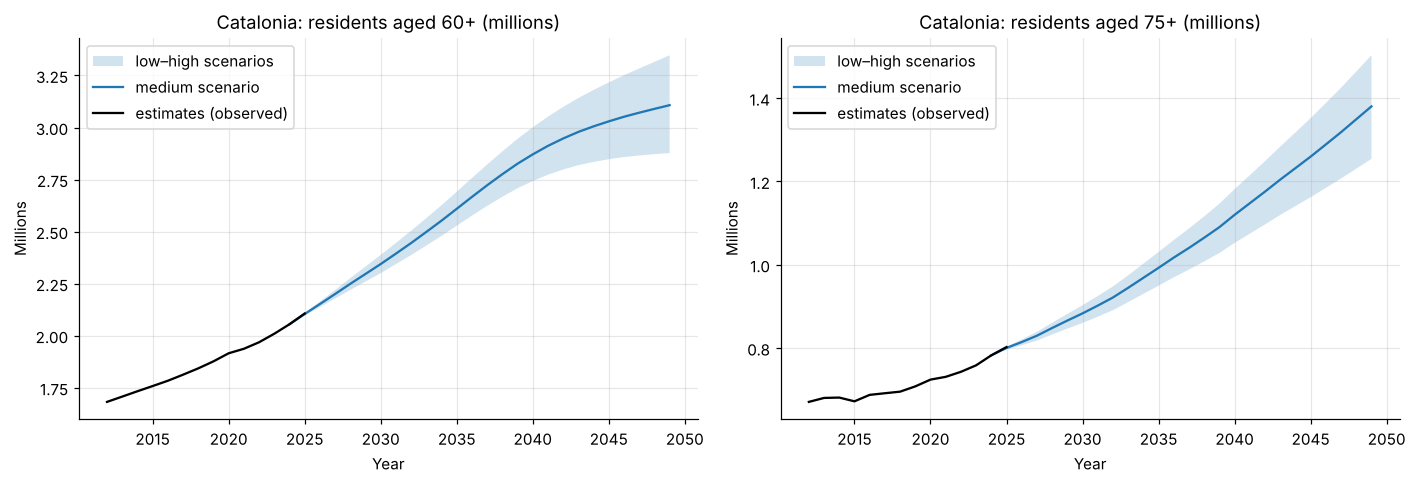

In [22]:
cat_proj = projected.loc[projected["comarca"] == CATALONIA].set_index(["scenario", "year"])
years_show = [2025, 2030, 2035, 2040]
view = cat_proj.loc[(slice(None), years_show), ["pop_total", "pop_60_plus", "share_60_plus", "pop_75_plus", "share_75_plus"]]
display(view.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, col in (("60+", "pop_60_plus"), ("75+", "pop_75_plus")):
    ax = axes[0] if name == "60+" else axes[1]
    s = {sc: cat_proj.loc[sc][col] / 1e6 for sc in ("low", "medium", "high")}
    ax.fill_between(s["medium"].index, s["low"], s["high"], alpha=0.2, label="low–high scenarios")
    ax.plot(s["medium"].index, s["medium"], label="medium scenario")
    ax.plot(ce.index, ce[col] / 1e6, color="black", label="estimates (observed)")
    ax.set(title=f"Catalonia: residents aged {name} (millions)", xlabel="Year", ylabel="Millions")
    ax.legend()
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_catalonia_projections.png", bbox_inches="tight"); plt.show()

In [23]:
pw = projected.loc[projected["comarca"] != CATALONIA].pivot_table(
    index="comarca", columns=["scenario", "year"], values=["pop_60_plus", "pop_75_plus", "share_60_plus"])

proj_table = pd.DataFrame(index=pw.index)
proj_table["pop_60_plus_2025_proj"] = pw[("pop_60_plus", "medium", 2025)]
for end in (2035, 2040):
    for sc in ("low", "medium", "high"):
        proj_table[f"pct_change_60_plus_2025_{end}_{sc}"] = 100 * (pw[("pop_60_plus", sc, end)] / pw[("pop_60_plus", sc, 2025)] - 1)
proj_table["abs_change_60_plus_2025_2040_medium"] = pw[("pop_60_plus", "medium", 2040)] - pw[("pop_60_plus", "medium", 2025)]
proj_table["pct_change_75_plus_2025_2040_medium"] = 100 * (pw[("pop_75_plus", "medium", 2040)] / pw[("pop_75_plus", "medium", 2025)] - 1)
proj_table["share_60_plus_2025_medium"] = pw[("share_60_plus", "medium", 2025)]
proj_table["share_60_plus_2040_medium"] = pw[("share_60_plus", "medium", 2040)]
proj_table["pp_change_share_60_plus_2025_2040_medium"] = proj_table["share_60_plus_2040_medium"] - proj_table["share_60_plus_2025_medium"]

for sc in ("low", "medium", "high"):
    c0, c1 = cat_proj.loc[(sc, 2025), "pop_60_plus"], cat_proj.loc[(sc, 2040), "pop_60_plus"]
    print(f"Catalonia 60+ 2025->2040, {sc:6s}: {c1 - c0:+,.0f} ({100*(c1/c0-1):+.1f} %)")
print("Comarques with projected 60+ decline 2025-2040 (medium):",
      proj_table.index[proj_table["pct_change_60_plus_2025_2040_medium"] < 0].tolist())
print("... even in the high scenario:",
      proj_table.index[proj_table["pct_change_60_plus_2025_2040_high"] < 0].tolist())

display(proj_table.sort_values("abs_change_60_plus_2025_2040_medium", ascending=False)[
    ["pop_60_plus_2025_proj", "abs_change_60_plus_2025_2040_medium",
     "pct_change_60_plus_2025_2040_low", "pct_change_60_plus_2025_2040_medium", "pct_change_60_plus_2025_2040_high",
     "pct_change_75_plus_2025_2040_medium", "share_60_plus_2025_medium", "share_60_plus_2040_medium"]].round(1))

Catalonia 60+ 2025->2040, low   : +645,368 (+30.8 %)
Catalonia 60+ 2025->2040, medium: +766,790 (+36.4 %)
Catalonia 60+ 2025->2040, high  : +890,660 (+42.2 %)
Comarques with projected 60+ decline 2025-2040 (medium): []
... even in the high scenario: []


,pop_60_plus_2025_proj,abs_change_60_plus_2025_2040_medium,pct_change_60_plus_2025_2040_low,pct_change_60_plus_2025_2040_medium,pct_change_60_plus_2025_2040_high,pct_change_75_plus_2025_2040_medium,share_60_plus_2025_medium,share_60_plus_2040_medium
comarca,,,,,,,,
Barcelonès,627329.0,118524.0,13.6,18.9,22.5,14.9,26.5,30.5
Vallès Occidental,236509.0,103291.0,38.9,43.7,48.5,50.9,24.3,32.9
Baix Llobregat,215585.0,90255.0,36.8,41.9,46.9,38.8,25.2,33.8
Maresme,128439.0,57295.0,39.5,44.6,49.8,57.8,26.9,35.9
Vallès Oriental,107161.0,53069.0,44.7,49.5,54.3,57.6,24.9,34.5
Tarragonès,68731.0,34257.0,42.1,49.8,60.1,61.6,24.4,32.3
Baix Camp,53116.0,26539.0,42.9,50.0,59.2,65.5,25.4,33.3
Garraf,43624.0,23687.0,45.1,54.3,66.7,66.6,26.3,35.8
Segrià,56234.0,23279.0,35.2,41.4,47.9,47.8,25.4,32.9


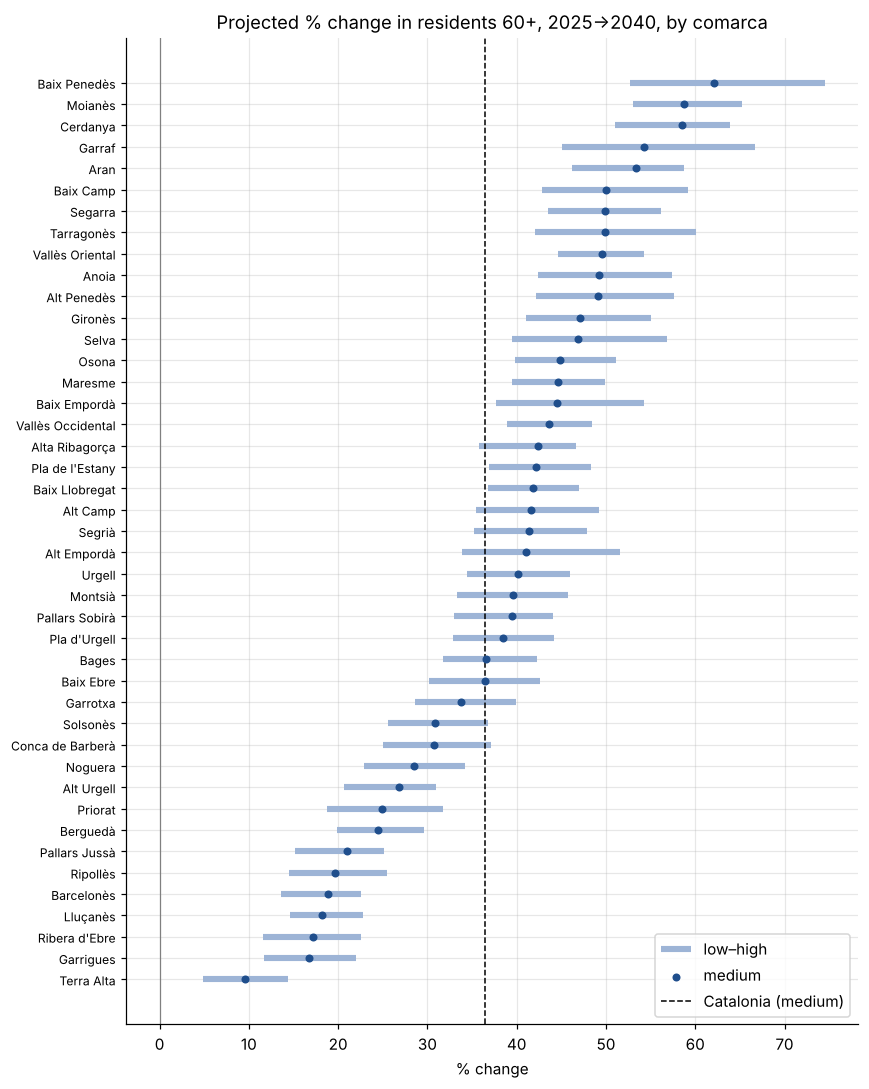

In [24]:
pt = proj_table.sort_values("pct_change_60_plus_2025_2040_medium")
fig, ax = plt.subplots(figsize=(8, 10))
y = np.arange(len(pt))
ax.hlines(y, pt["pct_change_60_plus_2025_2040_low"], pt["pct_change_60_plus_2025_2040_high"], color="#9DB4D6", lw=4, label="low–high")
ax.scatter(pt["pct_change_60_plus_2025_2040_medium"], y, color="#1F4E8C", zorder=3, s=18, label="medium")
ax.axvline(100 * (cat_proj.loc[("medium", 2040), "pop_60_plus"] / cat_proj.loc[("medium", 2025), "pop_60_plus"] - 1),
           color="black", ls="--", lw=1, label="Catalonia (medium)")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, pt.index, fontsize=8)
ax.set(title="Projected % change in residents 60+, 2025→2040, by comarca", xlabel="% change")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_projected_change_60plus_2025_2040.png", bbox_inches="tight"); plt.show()

### 6.7 Context: income and seasonal population (descriptive)

These indicators refer to **all residents/households**, not to seniors, and to different years (RFDB 2023 provisional, ETCA 2024). They are placed **side by side** with the demographic indicators and are not combined into a score.

In [25]:
context = (table_2025.set_index("comarca")[["pop_60_plus", "share_60_plus", "share_75_plus", "rank_size_60_plus", "rank_share_60_plus"]]
           .join(change_2021_2025[["pct_change_60_plus"]].rename(columns={"pct_change_60_plus": "pct_change_60_plus_2021_2025"}))
           .join(proj_table[["pct_change_60_plus_2025_2040_medium"]])
           .join(rfdb[["rfdb_per_capita_eur_2023", "rfdb_index_cat100_2023"]])
           .join(etca[["etca_pct_of_resident_2024"]]))
assert context.notna().all().all()
display(context.sort_values("pop_60_plus", ascending=False).round(1))

print("Spearman rank correlations (descriptive, n = 43):")
display(context[["pop_60_plus", "share_60_plus", "pct_change_60_plus_2021_2025", "pct_change_60_plus_2025_2040_medium",
                 "rfdb_per_capita_eur_2023", "etca_pct_of_resident_2024"]].corr(method="spearman").round(2))

,pop_60_plus,share_60_plus,share_75_plus,rank_size_60_plus,rank_share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,rfdb_per_capita_eur_2023,rfdb_index_cat100_2023,etca_pct_of_resident_2024
comarca,,,,,,,,,,
Barcelonès,631118,26.3,11.0,1,26,4.4,18.9,23632.0,113.7,101.8
Vallès Occidental,236586,24.4,8.8,2,41,10.7,43.7,21314.0,102.5,96.9
Baix Llobregat,215903,25.2,9.7,3,36,9.7,41.9,21188.0,101.9,95.6
Maresme,128349,26.9,9.8,4,21,11.2,44.6,20916.0,100.6,99.9
Vallès Oriental,107069,24.8,8.9,5,38,11.8,49.5,20515.0,98.7,95.0
Tarragonès,68732,24.6,8.6,6,40,12.9,49.8,17903.0,86.1,123.4
Segrià,56189,25.4,9.3,7,34,9.5,41.4,18371.0,88.4,99.2
Baix Camp,52992,25.5,9.0,8,32,12.9,50.0,17917.0,86.2,109.2
Bages,51670,27.5,10.5,9,19,8.2,36.5,19637.0,94.5,96.6


Spearman rank correlations (descriptive, n = 43):


,pop_60_plus,share_60_plus,pct_change_60_plus_2021_2025,pct_change_60_plus_2025_2040_medium,rfdb_per_capita_eur_2023,etca_pct_of_resident_2024
pop_60_plus,1.00,-0.58,0.34,0.30,0.39,-0.20
share_60_plus,-0.58,1.00,-0.70,-0.76,-0.34,0.18
pct_change_60_plus_2021_2025,0.34,-0.70,1.00,0.93,0.22,0.07
pct_change_60_plus_2025_2040_medium,0.30,-0.76,0.93,1.00,0.20,0.04
rfdb_per_capita_eur_2023,0.39,-0.34,0.22,0.20,1.00,-0.35
etca_pct_of_resident_2024,-0.20,0.18,0.07,0.04,-0.35,1.00


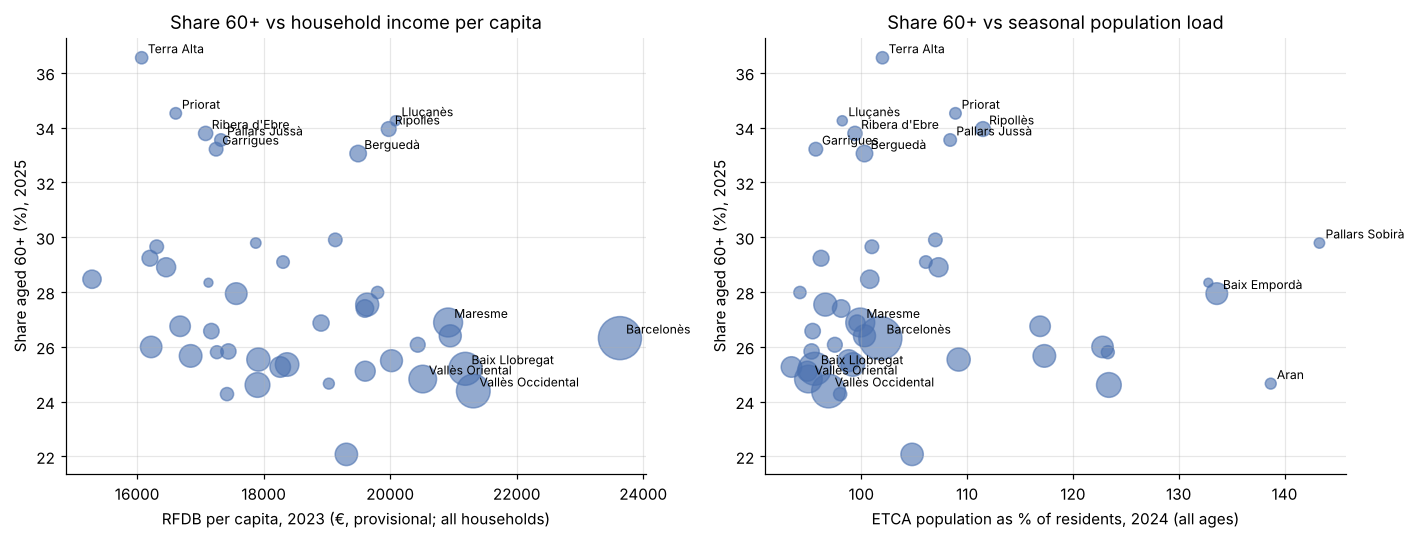

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, xlabel in ((axes[0], "rfdb_per_capita_eur_2023", "RFDB per capita, 2023 (€, provisional; all households)"),
                        (axes[1], "etca_pct_of_resident_2024", "ETCA population as % of residents, 2024 (all ages)")):
    ax.scatter(context[col], context["share_60_plus"], s=np.sqrt(context["pop_60_plus"]), alpha=0.6, color="#4C72B0")
    for name, r in context.iterrows():
        if r["pop_60_plus"] > 90_000 or r["share_60_plus"] > 31 or r[col] > context[col].quantile(0.93):
            ax.annotate(name, (r[col], r["share_60_plus"]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.set(xlabel=xlabel, ylabel="Share aged 60+ (%), 2025")
axes[0].set_title("Share 60+ vs household income per capita")
axes[1].set_title("Share 60+ vs seasonal population load")
plt.tight_layout(); plt.savefig(REPORTS_FIGURES / "03_context_income_seasonality.png", bbox_inches="tight"); plt.show()

### 6.8 Export of processed tables

Outputs go to `data/processed/` (regenerable, not versioned). Figures go to `reports/figures/`.

In [27]:
mun_to_comarca.to_csv(DATA_PROCESSED / "municipality_comarca_2025-01-01.csv", index=False, encoding="utf-8-sig")
table_2025.to_csv(DATA_PROCESSED / "comarca_senior_indicators_2025.csv", index=False, encoding="utf-8-sig")
trends.drop(columns="age_sum").to_csv(DATA_PROCESSED / "comarca_senior_trends_2011_2025_constant_boundaries.csv", index=False, encoding="utf-8-sig")
projected.drop(columns="age_sum").to_csv(DATA_PROCESSED / "comarca_senior_projections_base2024.csv", index=False, encoding="utf-8-sig")
context.reset_index().to_csv(DATA_PROCESSED / "comarca_senior_context_table.csv", index=False, encoding="utf-8-sig")
print(sorted(p.name for p in DATA_PROCESSED.glob("comarca_*")))

['comarca_senior_context_table.csv', 'comarca_senior_indicators_2025.csv', 'comarca_senior_projections_base2024.csv', 'comarca_senior_trends_2011_2025_constant_boundaries.csv']


## 7. Interpretation

The points below separate **facts** (measured in the data above), **observations** (patterns read from those facts) and **hypotheses** (to be tested later, not conclusions).

**Size (facts).** On 1 Jan 2025 Catalonia had **2.11 million residents aged 60+** (25.9 %), 1.60 million aged 65+ (19.7 %) and 0.80 million aged 75+ (9.9 %). The senior population is **highly concentrated**: three comarques (Barcelonès, Vallès Occidental, Baix Llobregat) hold 51 % of all residents aged 60+, ten hold 76 %, and Barcelonès alone holds 30 %. At the other end, 18 comarques have fewer than 10,000 residents aged 60+.

**Concentration (facts).** The share aged 60+ ranges from 22.1 % (Gironès) to 36.5 % (Terra Alta). The highest shares are in small, mostly interior or mountain comarques: Terra Alta, Priorat, Lluçanès, Ripollès, Ribera d'Ebre, Pallars Jussà, Garrigues and Berguedà, all at or above 33 %. None of these has more than 14,000 residents aged 60+.

**Observation: size and share point to different places.** The rank correlation between size and share is **−0.58**. Comarques with the most seniors tend to have average or below-average shares, and those with the highest shares tend to have the fewest seniors. A "most aged" comarca is therefore not a "largest senior market", and any territorial prioritisation has to state explicitly which of the two it values. This confirms, at comarca level, what notebook 01 observed for municipalities.

**Threshold sensitivity (facts).** Size rankings are practically identical for 60+, 65+ and 75+ (Spearman ≥ 0.998; same top 10). Share rankings are robust between 60+ and 65+ (0.98) and somewhat less so for 75+ (0.92), with 9 of the top 10 in common. *Observation:* the choice of threshold changes absolute counts a lot (2.11 M vs 0.80 M) but changes **which comarques stand out** very little. The threshold decision matters more for market sizing than for territorial selection.

**Recent trends (facts, constant boundaries).** Between 2021 and 2025 the 60+ population grew by **+169,000 (+8.7 %)**, while the total population grew by 4.8 %. It grew in **all 43 comarques**, and its share rose in 42. The exception is Barcelonès, where the 60+ population grew by 4.4 % but the total population grew faster, by 5.7 %. Relative growth was fastest in the metropolitan ring and on the coast (Baix Penedès, Aran, Garraf, Moianès, Selva, Tarragonès, Baix Camp: about 13–16 %) and slowest in the most aged comarques (Terra Alta 0.5 %, Ripollès 4.5 %, Garrigues 4.8 %). Over 2011–2025, with the methodological caveat, the 60+ population grew by +25 %; Terra Alta is the only comarca where it fell.

**Observation: where ageing is "happening".** The share aged 60+ is strongly *negatively* associated with recent 60+ growth (ρ = −0.70). Comarques that are already old are growing slowly in senior numbers, while the large, younger metropolitan and coastal comarques add the most seniors in both absolute and relative terms.

**Projections (Idescat scenarios, not forecasts).** From 2025 to 2040 the 60+ population is projected to grow by **+31 % (low), +36 % (medium) and +42 % (high)**. In the medium scenario that is +767,000, to 2.87 million (32.9 % of residents). The 75+ population grows by about +40 % (medium), to 1.12 million. Every comarca grows in every scenario. The largest absolute increases are in Barcelonès (+119,000), Vallès Occidental (+103,000) and Baix Llobregat (+90,000); the smallest relative ones are in Terra Alta, Garrigues, Ribera d'Ebre, Lluçanès, Barcelonès and Ripollès (below 20 %, medium). Projected growth closely mirrors recent growth (ρ = 0.93), which is expected because projections build on recent demographic behaviour. They are therefore not independent evidence.

**Context (descriptive associations, n = 43).** Household income per capita (RFDB 2023, all households) is moderately higher in comarques with more seniors (ρ = 0.39) and lower where the senior *share* is high (ρ = −0.34). Most high-share interior comarques are below the Catalan average, although Ripollès, Berguedà and Lluçanès are close to it (index 94–97). Seasonal load (ETCA 2024, all ages) is essentially unrelated to the senior share (ρ = 0.18). The highest loads are in the Pyrenees (Pallars Sobirà, Aran, Alta Ribagorça) and on the Costa Brava and Costa Daurada (Baix Empordà, Tarragonès, Alt Empordà).

**Costa Brava, the initial case (observation).** The three Costa Brava comarques (Alt Empordà, Baix Empordà, Selva) are **mid-sized** senior populations (39,000–48,000 aged 60+, ranks 10–15) with shares **close to the Catalan average** (25.7–27.9 %). Their 60+ population is growing faster than average, and they have high seasonal loads. In demographic terms they are not exceptional, which supports the decision to frame the market at Catalonia level.

**Hypotheses arising (not tested here).**
- H1: Two territorial profiles may call for different marketplace logics. (a) In large, dense, fast-growing metropolitan and coastal comarques, many seniors and many organisers suggest the problem may be *discovery among abundant supply*. (b) In small, highly aged, slow-growing interior comarques, few seniors are spread out and the problem may be *scarce or poorly publicised supply and mobility*. Testable through supply mapping and the survey.
- H2: In high-seasonality comarques, resident-only figures may understate the senior population present for part of the year (second-home owners, seasonal visitors). Testable only with other sources (e.g. age-specific tourism or second-residence data), if they exist.
- H3: The fast growth of 60+ in the metropolitan ring will increase demand for activities faster there than existing supply. Requires supply data to assess.

## 8. Limitations

- **Population ≠ market.** All figures describe residents in an age range. They say nothing about interest in activities, willingness to pay, digital use or current participation. Those require the demand research (survey and interviews).
- **Age thresholds are analytical conventions.** The 60+, 65+ and 75+ groups are heterogeneous (health, employment, mobility, digital skills). The 60–74 vs 75+ split is a first proxy for this heterogeneity, not a segmentation.
- **2011 comparability.** The 2011 census was partly survey-based and rounded, while 2021+ uses the register-based annual census. 2011→2025 changes carry this methodological break, so 2021→2025 is the homogeneous comparison.
- **Boundaries.** Trends use the 1 Jan 2025 division rebuilt from municipalities. They will differ from figures published by Idescat under the boundaries in force at the time (by design). The July 2025 move of Aiguafreda to Osona is *not* applied. Future work using the post-2025 division should update `src/tfg/territory.py`.
- **Projections are scenarios, not forecasts.** They depend on Idescat's fertility, mortality and migration assumptions (base 2024). The low–high range shows assumption sensitivity, not a confidence interval. Comarca projections for small comarques are more uncertain.
- **Residents only.** Census and projections count residents. Second-home owners and seasonal senior visitors (relevant on the coast and in the Pyrenees) are not captured, and ETCA is not age-specific.
- **Context indicators** (RFDB, ETCA) refer to all households or all ages and to other years (2023, 2024). Correlations are descriptive associations across 43 units, not evidence of causal relationships or of senior purchasing power.
- **Comarca averages hide internal heterogeneity** (e.g. Barcelona city vs other Barcelonès municipalities). Municipal analysis remains necessary for supply mapping and fieldwork selection.

## 9. Conclusions and next steps

**Conclusions (from the data in this notebook)**

1. The potential **demographic base** is large and growing. It ranges from 0.8 M to 2.1 M residents depending on the threshold, and is projected to grow by about 30–42 % (60+) by 2040 in every comarca and every scenario. Demography alone does not argue *against* the idea. It also does **not** show demand, which still has to be established.
2. The base is **territorially concentrated**: half of all seniors live in three comarques. Absolute size and relative ageing point to different comarques, so both must be reported side by side, never merged into a single score.
3. Rankings are **robust to the threshold** (60+, 65+, 75+), so the threshold can be chosen on market or product grounds later without changing the territorial picture much.
4. Senior growth is fastest in the **metropolitan ring and coastal comarques**, not in the comarques that are already the most aged.

**Next steps (recommended)**

- *Select comarques for detailed work* (supply inventory, survey) that cover the profiles observed. For example: one large metropolitan comarca, one fast-growing coastal one (continuity with the Costa Brava case: Baix Empordà or Selva) and one highly aged interior one (e.g. Ripollès, Berguedà, Terra Alta). To agree with the tutor.
- *Add context variables* available from Idescat at comarca and municipal level: households and people living alone by age (`censph` household indicators), education level by age, degree of urbanisation (`degurba`), density, and the territorial socioeconomic index (`ist`). Also look for age-specific sources on digital use and cultural participation (INE / Idescat surveys).
- *Municipal analysis* within the selected comarques, using the constant-boundary municipal data and the code-based mapping built here.
- *Start the supply-side inventory* design (casals, associations, municipal agendas). Online records are a sample, not a census.
- *Discuss with the tutor:* which thresholds to report as primary; and whether to use the medium projection scenario as the reference, with low and high as the sensitivity range.